# Chart Geometry and Graph Waypoints: Current Atlas-DeePC Ablation

Paired **100-seed experiment, seeds 211--310**, using the current baseline's
**iterative terminal-reference selection from N=10 candidates** in every method.
All four variants are run afresh; the baseline is **linear charts + graph waypoints**.

| Method | Current-chart representation | Reference supplied to DeePC |
|---|---|---|
| Linear charts + graph waypoints (baseline) | Uncentered SVD, zero offset | Graph waypoint, then selected terminal reference |
| Affine charts + graph waypoints | Centered SVD plus chart mean | Graph waypoint, then selected terminal reference |
| Linear charts + terminal reference only | Uncentered SVD, zero offset | Selected terminal reference at every step |
| Affine charts + terminal reference only | Centered SVD plus chart mean | Selected terminal reference at every step |

**Important:** "terminal reference only" removes graph **waypoints**, not graph costs
from N=10 terminal-reference selection. The terminal configuration can still change
at each step. Thus this isolates waypoint guidance while retaining the new goal policy;
it is not a completely graph-free controller.

The same offline data, 48 physical-configuration charts, rank 60, QP weights,
constraints, current-chart localization, solver, and 320-step task are used throughout.
There is no contextual atlas or rescue, fitted dynamics, or feedback fallback.
These previously inspected seeds form an exploratory paired ablation, not a new
untouched evaluation set. The old fixed-reference 500-seed notebook and results
remain archived and are not mixed into this panel.


In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_deepc_mpl")
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[name] = "1"
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/basis_routing_iterative_ablation.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import baseline_atlas_deepc as baseline
import basis_routing_iterative_ablation as experiment
get_ipython().run_line_magic("matplotlib", "inline")

SEEDS = list(range(211, 311))
RUN_EXPERIMENTS = False
WORKERS = 4
OUTPUT_DIR = experiment.OUTPUT_DIR
config = baseline.default_config()
METHODS = list(experiment.METHODS)
assert config.clusters == 48 and config.svd_rank == 60 and config.steps == 320
assert config.formulation == "svd_current" and config.target_matrix_mode == "current"
print(f"{len(SEEDS)} paired seeds: {SEEDS[0]}--{SEEDS[-1]}; {len(METHODS)} methods")
display(pd.Series({"charts": config.clusters, "rank": config.svd_rank, "candidates before deduplication": 10,
                   "control steps": config.steps, "source-target separation (m)": config.goal_source_target_min_distance}))
display(HTML("<details><summary>Full shared controller configuration</summary>"
             + pd.Series(vars(config)).to_frame("value").to_html() + "</details>"))


100 paired seeds: 211--310; 4 methods


charts                              48.00
rank                                60.00
candidates before deduplication     10.00
control steps                      320.00
source-target separation (m)         0.06
dtype: float64

,value
clusters,48
cluster_seed,11
clustering_input_weight,0.0
clustering_method,minibatch_kmeans
clustering_feature_mode,plant_joint_configuration
clustering_subspace_rank,6
clustering_max_iter,20
clustering_configuration_weight,1.0
clustering_velocity_weight,1.0
clustering_fingertip_weight,1.0


## 1. Chart Representation

Let $X_k$ contain the full input-output Hankel columns assigned to current chart $k$.
DeePC predicts its stacked input-output trajectory $b$ from the following matrix:

**Current baseline: linear-subspace chart**
$$U_k=\operatorname{SVD}_{60}(X_k),\qquad b=U_kg.$$

**Ablation: affine-subspace chart**
$$\bar h_k=\operatorname{mean}(X_k),\qquad
V_k=\operatorname{SVD}_{60}(X_k-\bar h_k),\qquad b=\bar h_k+V_kg.$$

Here SVD denotes the retained left singular vectors. Both representations have 60
orthonormal basis columns. The same coefficient-bound rule is recalculated in the
respective coordinates: for $a_i=U_k^Tx_i$ or $a_i=V_k^T(x_i-\bar h_k)$, use
$\operatorname{mean}(a)\pm3\operatorname{std}(a)$ with the existing numerical floor.
The coefficient regularization $\lambda_g\|g\|_2^2$ and all other QP terms are unchanged.
Thus this tests centering and its associated coordinate representation without retuning.

## 2. Terminal Selection and Waypoint Ablation

**Identical N=10 policy in all methods:** once the online target $p^\star$ is known,
exclude configurations whose source episode target lies within 6 cm of $p^\star$.
Keep the 10 remaining configurations with smallest Euclidean fingertip error, then
keep the closest candidate per distinct chart. At every step, select the candidate
chart with minimum precomputed shortest-path cost from the current chart. Construct
$y_t^\star$ using its sampled posture, zero velocities, and exact target coordinates.

- **Graph waypoints:** follow the current route's next-chart medoid; within 7 cm,
  latch terminal-reference mode. The latch does not freeze N=10 goal reselection.
- **Terminal reference only:** supply $r_t=y_t^\star$ across the prediction horizon
  from the first step. Skip route reconstruction and medoid waypoints. Current-chart
  localization, N=10 route-cost selection, and the current chart's basis remain active.

All methods have identical initial candidate sets and initially selected terminal
configuration for each seed. Later terminal selections can differ because the
controllers visit different charts. No method is asserted to have a fixed goal posture.

## 3. Execute or Load the Panel

The saved panel contains 400 complete rollouts. `RUN_EXPERIMENTS=False` only loads
results. Set it to `True` to run/resume; compatible checkpoints are retained.

Four concurrent worker processes use one numerical-library thread each. Method order
rotates across seeds. Both chart representations are warmed up on seed 210 (10 steps
each) per worker. All 320 steps count for success; timing aggregates omit the first
five steps of each evaluated rollout. These are shared-computer concurrent wall-clock
measurements, **not isolated serial latency** and not directly comparable to the
baseline notebook's separately recorded timings.


In [2]:
if RUN_EXPERIMENTS:
    payload = experiment.run_panel(SEEDS, OUTPUT_DIR, WORKERS)
else:
    payload = json.loads((OUTPUT_DIR / "summary.json").read_text())
assert payload["version"] == experiment.VERSION
assert payload["signature"]["candidate_count"] == 10
assert payload["seeds"] == SEEDS
assert payload["signature"]["config"] == {k: v for k, v in vars(config).items() if k != "seed"}
frame = pd.DataFrame(payload["results"])
assert len(frame) == len(SEEDS)*len(METHODS)
assert not frame.duplicated(["method", "seed"]).any()
for method in METHODS:
    assert set(frame.loc[frame.method == method, "seed"]) == set(SEEDS)
assert (frame.candidate_count == 10).all() and frame.dynamic_terminal_reference.all()
assert (frame.groupby("seed").initial_goal_index.nunique() == 1).all()
frame["strict_success"] = frame.success_30 & frame.success_100
print(f"Loaded {len(frame)} complete rollouts; all variants use iterative N=10 terminal selection.")


Loaded 400 complete rollouts; all variants use iterative N=10 terminal selection.


## 4. Success and Paired Outcomes

Strict success requires **mean error <1 cm and maximum error <2 cm over both the
final-30 and final-100 windows**. Reporting only the minimum error or the final frame
would not establish success under this criterion.


,successes,trials,success rate (%),median final-100 error (mm),unsolved QP steps
method,,,,,
Linear charts + graph waypoints (baseline),93,100,93.0,2.062,0
Affine charts + graph waypoints,91,100,91.0,2.185,0
Linear charts + terminal reference only,83,100,83.0,2.440,0
Affine charts + terminal reference only,81,100,81.0,2.409,0


,variant,repaired,regressed,net successes
0,Affine charts + graph waypoints,1,3,-2
1,Linear charts + terminal reference only,0,10,-10
2,Affine charts + terminal reference only,0,12,-12


reference method,variant,repaired,regressed,net successes,repaired seeds,regressed seeds
Linear charts + graph waypoints (baseline),Affine charts + graph waypoints,1,3,-2,[296],"[231, 254, 266]"
Linear charts + graph waypoints (baseline),Linear charts + terminal reference only,0,10,-10,[],"[236, 237, 241, 262, 269, 284, 292, 293, 294, 306]"
Linear charts + graph waypoints (baseline),Affine charts + terminal reference only,0,12,-12,[],"[231, 236, 237, 241, 254, 262, 266, 269, 284, 287, 293, 294]"
Linear charts + terminal reference only,Affine charts + terminal reference only,2,4,-2,"[292, 306]","[231, 254, 266, 287]"
Affine charts + graph waypoints,Affine charts + terminal reference only,0,10,-10,[],"[236, 237, 241, 262, 269, 284, 287, 293, 294, 296]"


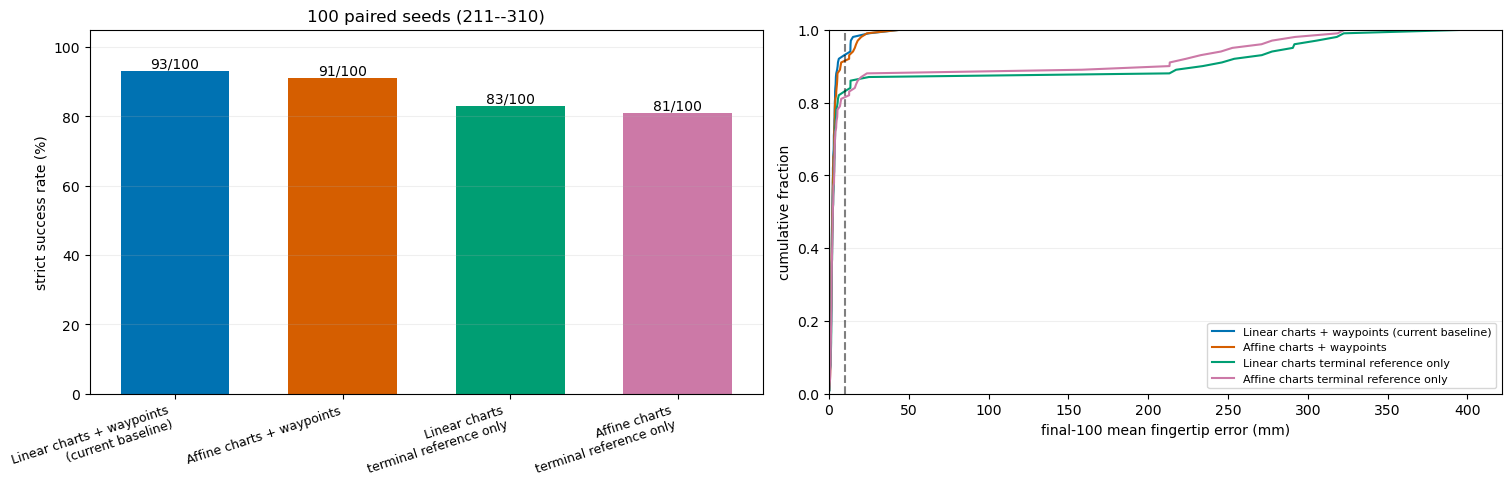

In [3]:
records = []
for method in METHODS:
    rows = frame.loc[frame.method == method]
    count = int(rows.strict_success.sum())
    records.append({"method": method, "successes": count, "trials": len(rows),
                    "success rate (%)": 100*count/len(rows),
                    "median final-100 error (mm)": 1000*rows.mean_last_100.median(),
                    "unsolved QP steps": int(rows.unsolved_steps.sum())})
summary = pd.DataFrame(records).set_index("method").loc[METHODS]
display(summary.style.format({"success rate (%)": "{:.1f}", "median final-100 error (mm)": "{:.3f}"}))
success = frame.pivot(index="seed", columns="method", values="strict_success").loc[SEEDS]
paired = []
for first, second in [(METHODS[0], m) for m in METHODS[1:]] + [(METHODS[2], METHODS[3]), (METHODS[1], METHODS[3])]:
    repaired = success.index[~success[first] & success[second]].tolist()
    regressed = success.index[success[first] & ~success[second]].tolist()
    paired.append({"reference method": first, "variant": second, "repaired": len(repaired),
                   "regressed": len(regressed), "net successes": len(repaired)-len(regressed),
                   "repaired seeds": repaired, "regressed seeds": regressed})
display(pd.DataFrame(paired[:3]).drop(columns=["reference method", "repaired seeds", "regressed seeds"]))
display(HTML("<details><summary>All paired comparisons and seed lists</summary>"
             + pd.DataFrame(paired).to_html(index=False) + "</details>"))
(OUTPUT_DIR / "paired_comparisons.json").write_text(json.dumps(paired, indent=2))
(OUTPUT_DIR / "method_summary.json").write_text(summary.reset_index().to_json(orient="records", indent=2))

colors = ["#0072B2", "#D55E00", "#009E73", "#CC79A7"]
labels = ["Linear charts + waypoints\n(current baseline)", "Affine charts + waypoints",
          "Linear charts\nterminal reference only", "Affine charts\nterminal reference only"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), constrained_layout=True)
x = np.arange(len(METHODS))
axes[0].bar(x, summary["success rate (%)"], color=colors, width=0.65)
axes[0].set(ylim=(0, 105), ylabel="strict success rate (%)", title="100 paired seeds (211--310)")
axes[0].set_xticks(x, labels, rotation=18, ha="right", fontsize=9)
for i, row in enumerate(summary.to_dict("records")):
    axes[0].text(i, row["success rate (%)"]+1, f"{row['successes']}/100", ha="center")
for method, color, label in zip(METHODS, colors, labels):
    errors = np.sort(1000*frame.loc[frame.method == method, "mean_last_100"])
    axes[1].plot(errors, np.arange(1, len(errors)+1)/len(errors), color=color, label=label.replace("\n", " "))
axes[1].axvline(10, color="black", linestyle="--", alpha=0.5)
axes[1].set(xlabel="final-100 mean fingertip error (mm)", ylabel="cumulative fraction", xlim=(0, None), ylim=(0, 1))
axes[1].legend(fontsize=8, loc="lower right")
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.savefig(OUTPUT_DIR / "success_comparison.png", dpi=170)
plt.show()
display(HTML(
    f"<p><strong>Observed differences from the current baseline:</strong> affine charts with waypoints "
    f"{summary.loc[METHODS[1], 'success rate (%)']-summary.loc[METHODS[0], 'success rate (%)']:+.0f} percentage points; "
    f"linear charts without waypoints {summary.loc[METHODS[2], 'success rate (%)']-summary.loc[METHODS[0], 'success rate (%)']:+.0f} points; "
    f"affine charts without waypoints {summary.loc[METHODS[3], 'success rate (%)']-summary.loc[METHODS[0], 'success rate (%)']:+.0f} points.</p>"
    "<p><strong>Interpretation:</strong> compare the affine-waypoint row with the current baseline "
    "to assess chart centering; compare the linear-terminal-only row with the baseline "
    "to assess waypoint guidance. The fourth row changes both components. "
    "These are descriptive outcomes on 100 previously inspected seeds, not evidence "
    "that one representation or routing policy is universally superior.</p>"
))


## 5. Computation by Module

Means, medians, p95, and p99 below are pooled over 31,500 timed steps per method.
Only means are stacked: module percentiles do not sum to the total percentile.
QP time includes problem construction, canonicalization, and the solve call.
Simulation stepping, saving, rendering, and offline SVD are excluded.

For terminal-only variants, the small routing timer contains reference-mode and
distance bookkeeping, **not path reconstruction**. Terminal-reference selection
still performs N=10 graph-cost lookups. Initial target search and worker setup are
reported separately. All timings below come from this new concurrent batch.


,mean_ms,median_ms,p95_ms,p99_ms
method,,,,
Linear charts + graph waypoints (baseline),37.373,33.857,57.953,80.621
Affine charts + graph waypoints,37.742,34.295,58.182,80.227
Linear charts + terminal reference only,38.524,34.927,58.805,79.848
Affine charts + terminal reference only,39.018,35.367,60.177,84.863


method,module,mean_ms,median_ms,p95_ms,p99_ms
Linear charts + graph waypoints (baseline),Chart localization,0.07193,0.06296,0.09946,0.25259
Linear charts + graph waypoints (baseline),Terminal-reference selection,0.01710,0.01483,0.01929,0.05658
Linear charts + graph waypoints (baseline),Waypoint routing / bookkeeping,0.00707,0.00612,0.00854,0.02308
Linear charts + graph waypoints (baseline),Chart representation retrieval,0.00083,0.00075,0.00104,0.00137
Linear charts + graph waypoints (baseline),QP construction and solve,37.23903,33.73377,57.82413,80.38760
Linear charts + graph waypoints (baseline),Other control-loop work,0.03735,0.03129,0.05217,0.12779
Linear charts + graph waypoints (baseline),Total online control,37.37331,33.85669,57.95267,80.62102
Affine charts + graph waypoints,Chart localization,0.07278,0.06300,0.09754,0.24596
Affine charts + graph waypoints,Terminal-reference selection,0.01688,0.01483,0.01921,0.05567
Affine charts + graph waypoints,Waypoint routing / bookkeeping,0.00725,0.00612,0.00846,0.02100


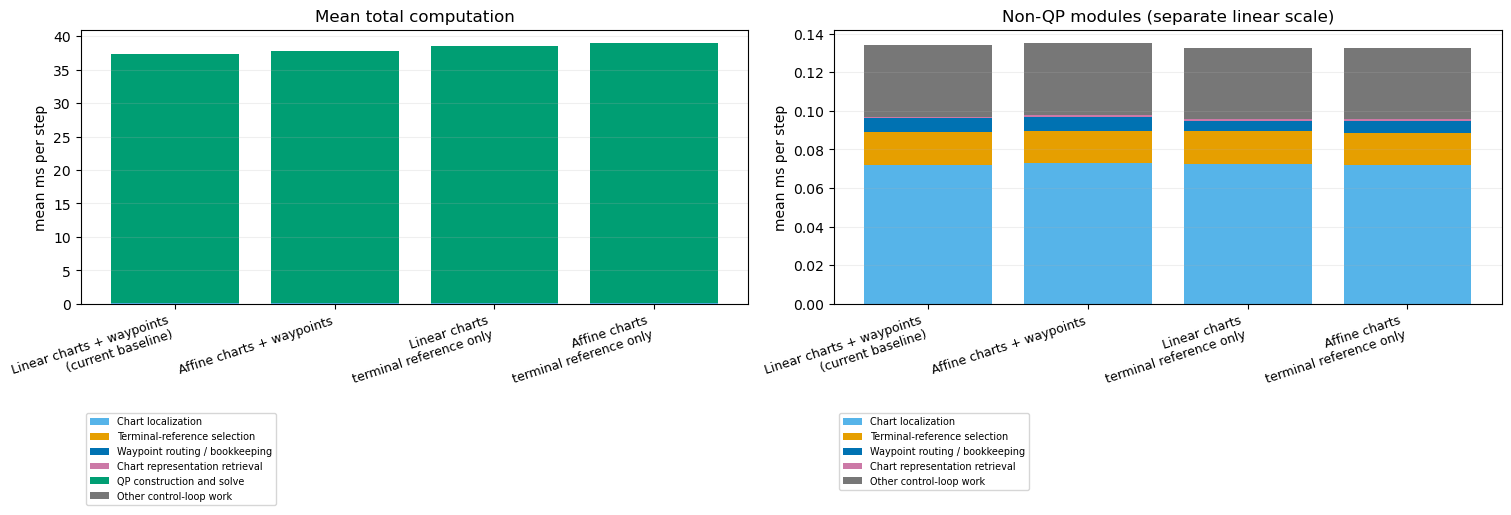

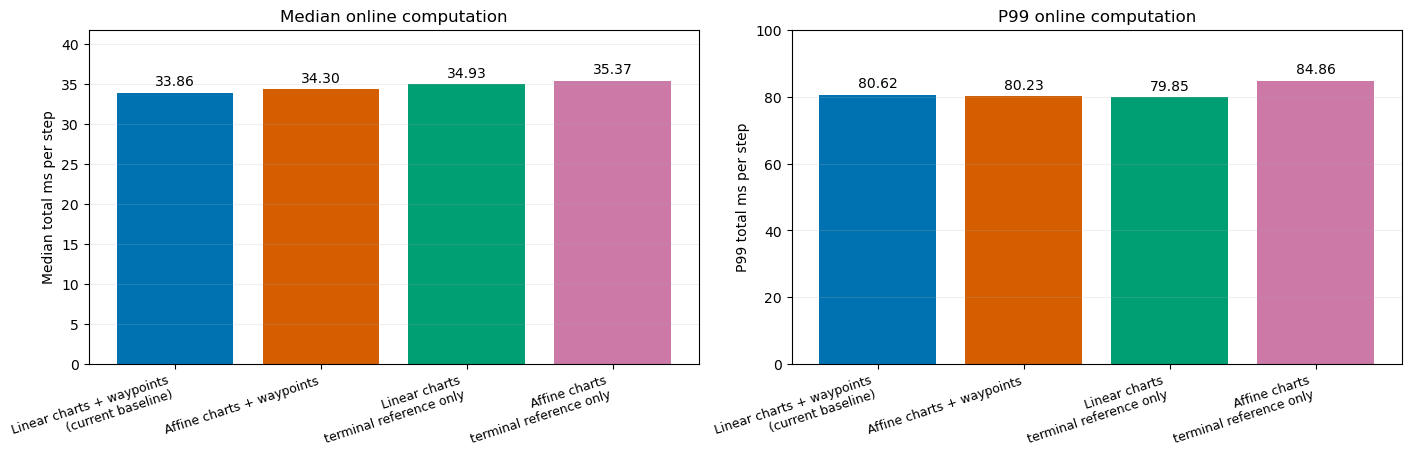

One-time target-neighborhood setup per rollout (ms):


,mean,median,p95
method,,,
Linear charts + graph waypoints (baseline),5.534,5.115,8.158
Affine charts + graph waypoints,5.465,5.099,7.678
Linear charts + terminal reference only,5.544,5.175,7.298
Affine charts + terminal reference only,5.742,5.099,7.677


Worker offline setup (seconds; includes data/atlas loading, chart caches and route tables):


,pid,offline_setup_seconds,warmup_seed,warmup_steps_per_geometry
0,68122,0.335084,210,10
1,68123,0.326383,210,10
2,68120,0.340183,210,10
3,68121,0.334013,210,10


In [4]:
timing_records = []
setup_records = []
for method in METHODS:
    timing = payload["timing"][method]
    assert timing["timed_steps"] == len(SEEDS)*(config.steps-5)
    timing_records.extend({"method": method, **row} for row in timing["modules"])
    setup_records.append({"method": method, **timing["one_time_goal_setup_ms"]})
timing_frame = pd.DataFrame(timing_records)
timing_frame["module"] = timing_frame["module"].replace({
    "Linear subspace retrieval": "Chart representation retrieval",
    "Graph routing": "Waypoint routing / bookkeeping",
})
totals = timing_frame.loc[timing_frame.module == "Total online control"].set_index("method").loc[METHODS]
display(totals[["mean_ms", "median_ms", "p95_ms", "p99_ms"]].round(3))
module_names = timing_frame.loc[(timing_frame.method == METHODS[0]) & (timing_frame.module != "Total online control"), "module"].tolist()
stage_means = timing_frame.pivot(index="method", columns="module", values="mean_ms").loc[METHODS, module_names]
np.testing.assert_allclose(stage_means.sum(axis=1), totals.mean_ms, atol=1e-6)
display(HTML("<details><summary>Full per-module timing table (ms)</summary>"
             + timing_frame.drop(columns="share_of_mean_total").round(5).to_html(index=False) + "</details>"))
stage_colors = ["#56B4E9", "#E69F00", "#0072B2", "#CC79A7", "#009E73", "#777777"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
bottom = np.zeros(len(METHODS))
for module, color in zip(module_names, stage_colors):
    values = stage_means[module].to_numpy()
    axes[0].bar(x, values, bottom=bottom, color=color, label=module)
    bottom += values
overhead_names = [name for name in module_names if name != "QP construction and solve"]
bottom = np.zeros(len(METHODS))
for module, color in zip(module_names, stage_colors):
    if module not in overhead_names:
        continue
    values = stage_means[module].to_numpy()
    axes[1].bar(x, values, bottom=bottom, color=color, label=module)
    bottom += values
for ax, title in zip(axes, ["Mean total computation", "Non-QP modules (separate linear scale)"]):
    ax.set(ylabel="mean ms per step", ylim=(0, None), title=title)
    ax.set_xticks(x, labels, rotation=18, ha="right", fontsize=9)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(0, -0.38))
fig.savefig(OUTPUT_DIR / "module_timing.png", dpi=170, bbox_inches="tight")
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
for ax, field, label in zip(axes, ["median_ms", "p99_ms"], ["Median", "P99"]):
    bars = ax.bar(x, totals[field], color=colors)
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set(ylim=(0, totals[field].max()*1.18), ylabel=f"{label} total ms per step", title=f"{label} online computation")
    ax.set_xticks(x, labels, rotation=18, ha="right", fontsize=9)
    ax.grid(axis="y", alpha=0.2)
fig.savefig(OUTPUT_DIR / "median_p99_timing.png", dpi=170)
plt.show()
print("One-time target-neighborhood setup per rollout (ms):")
display(pd.DataFrame(setup_records).set_index("method").loc[METHODS].round(3))
print("Worker offline setup (seconds; includes data/atlas loading, chart caches and route tables):")
display(pd.DataFrame(payload["worker_setup"]))


## 6. Seed-Level Behavior and Integrity

The plot defaults to seed 277. Change `SEED_TO_INSPECT` to any seed from this panel.
Full 320-step histories are shown, including late drift or terminal-reference changes.


,method,strict_success,mean_last_30,mean_last_100,goal_sample_switches,unsolved_steps
66,Linear charts + graph waypoints (baseline),True,0.000228,0.000228,0,0
166,Affine charts + graph waypoints,True,0.001352,0.001352,0,0
266,Linear charts + terminal reference only,True,0.000228,0.000228,0,0
366,Affine charts + terminal reference only,True,0.001352,0.001352,0,0


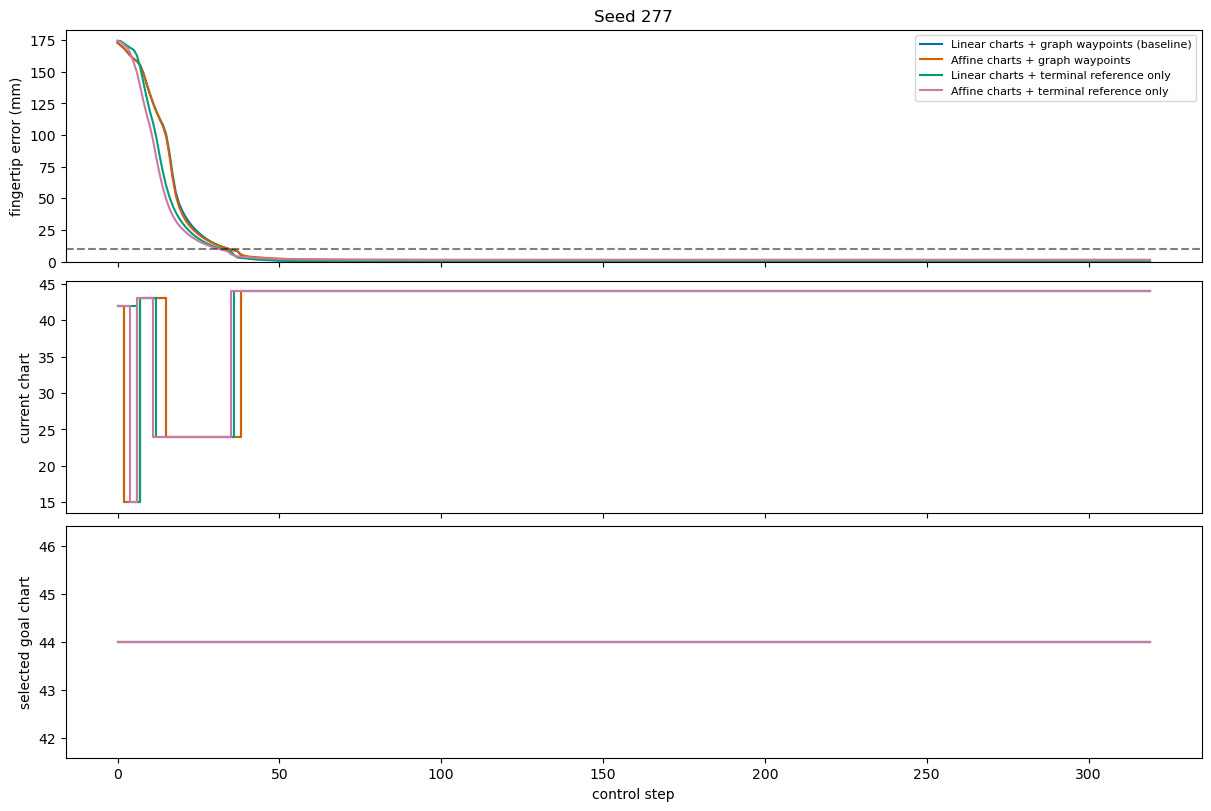

reproduced current-baseline rollouts                              100
matching baseline success labels                                  100
matching baseline terminal-selection histories                    100
maximum baseline output difference                                0.0
initial terminal reference shared across all four methods        True
minimum selected source-target separation (m)                0.062927
total unsolved QP steps                                             0
dtype: object

In [5]:
SEED_TO_INSPECT = 277
if SEED_TO_INSPECT in SEEDS:
    display(frame.loc[frame.seed == SEED_TO_INSPECT,
                      ["method", "strict_success", "mean_last_30", "mean_last_100", "goal_sample_switches", "unsolved_steps"]])
    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, constrained_layout=True)
    for method, color in zip(METHODS, colors):
        row = frame.loc[(frame.seed == SEED_TO_INSPECT) & (frame.method == method)].iloc[0]
        with np.load(row.result_path, allow_pickle=True) as trace:
            axes[0].plot(1000*trace["distance"], color=color, label=method)
            axes[1].step(np.arange(config.steps), trace["chart"], where="post", color=color)
            axes[2].step(np.arange(config.steps), trace["goal_chart"], where="post", color=color)
    axes[0].axhline(10, color="black", linestyle="--", alpha=0.5)
    axes[0].set(ylabel="fingertip error (mm)", ylim=(0, None), title=f"Seed {SEED_TO_INSPECT}")
    axes[0].legend(fontsize=8)
    axes[1].set_ylabel("current chart")
    axes[2].set(xlabel="control step", ylabel="selected goal chart")
    fig.savefig(OUTPUT_DIR / f"seed{SEED_TO_INSPECT}_diagnostic.png", dpi=150)
    plt.show()

assert not frame.fitted_dynamics_model.any()
assert not frame.online_nearest_trajectory_retrieval.any()
assert not frame.feedback_fallback.any()
assert (frame.minimum_selected_goal_source_separation >= config.goal_source_target_min_distance).all()
checks = pd.DataFrame(payload["baseline_reproduction"])
assert len(checks) == len(SEEDS) and checks.success_matches.all() and checks.goal_indices_match.all()
assert checks.max_output_difference.max() < 1e-10
display(pd.Series({
    "reproduced current-baseline rollouts": len(checks),
    "matching baseline success labels": int(checks.success_matches.sum()),
    "matching baseline terminal-selection histories": int(checks.goal_indices_match.sum()),
    "maximum baseline output difference": checks.max_output_difference.max(),
    "initial terminal reference shared across all four methods": bool((frame.groupby("seed").initial_goal_index.nunique() == 1).all()),
    "minimum selected source-target separation (m)": frame.minimum_selected_goal_source_separation.min(),
    "total unsolved QP steps": int(frame.unsolved_steps.sum()),
}))


## 7. Reproduction and Scope

```bash
python src/basis_routing_iterative_ablation.py --seed-start 211 --seed-stop 310 --workers 4
```

The new output directory is `experiments/routed_deepc_iid/basis_routing_iterative_n10_100/`.
It is separate from the old fixed-reference 500-seed results. Compatible traces resume;
changed settings or source files require a new output directory. No control experiments
are launched by this notebook unless `RUN_EXPERIMENTS=True`.

The archived notebook is
`archive/notebooks/ablation_affine_subspace_and_graph_routing_fixed_reference_500.ipynb`.
Do not combine its old reference-policy outcomes with the current N=10 ablation.
